# 04 · Análisis de Precios, Descuentos y Concentración por Categoría y Gama (Objetivo 1)

**DS3021 Análisis Computacional de Datos · Proyecto Final, Parte II**

**Objetivo Específico 1.** *Evaluar la magnitud, distribución y veracidad de los descuentos: cuantificar la brecha porcentual entre el precio de lista y precio por internet en las tres categorías tecnológicas, determinando qué líneas presentan rebajas más agresivas y cuáles mantienen precios de venta rígidos.*

Este notebook analiza el dataset procesado (`data/processed/falabella_processed.csv`, 1,037 registros y 16 variables) y exporta los resúmenes estadísticos en `data/analysis/` junto con las visualizaciones para el informe y la presentación:

1. **Concentración y Multimodalidad de Precios:** Gráficos de violín y tabla de dispersión relativa ($	ext{IQR Relativo} = 	ext{IQR}/	ext{Mediana} \times 100$).
2. **Estructura de Descuentos por Categoría y Gama (`low`, `mid`, `high`):** Boxplots comparativos del porcentaje de rebaja (`discount_pct`) y ahorro en soles (`discount_amount`).
3. **Relación Precio vs. Descuento Porcentual:** Diagramas de dispersión con rectas de tendencia y correlaciones de Pearson y Spearman.
4. **Veracidad de Descuentos y Anomalías Comerciales:** Descuentos extremos ($> 60\%$), efecto de equipos reacondicionados (`is_refurbished`) y paquetes promocionales (`is_bundle`).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

CATS = ["laptops", "phones", "tvs"]
TIERS = ["low", "mid", "high"]
FIG_DOCS = ROOT / "docs" / "img"
FIG_ANA = ROOT / "data" / "analysis" / "figures"
ANA_DIR = ROOT / "data" / "analysis"
FIG_DOCS.mkdir(parents=True, exist_ok=True)
FIG_ANA.mkdir(parents=True, exist_ok=True)


def say(text):
    display(Markdown(text))


def savefig(name):
    plt.savefig(FIG_DOCS / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.savefig(FIG_ANA / f"{name}.png", dpi=160, bbox_inches="tight")


df = pd.read_csv(ROOT / "data" / "processed" / "falabella_processed.csv")
print(f"Dataset procesado: {df.shape[0]} filas x {df.shape[1]} columnas")

Dataset procesado: 1037 filas x 16 columnas


## 1. Distribución de Precios, Concentración y Dispersión Relativa (IQR Relativo)

Como las distribuciones de precios en comercio electrónico presentan asimetría positiva (cola larga hacia equipos de gama ultra-alta), la media y la desviación estándar son sensibles a valores extremos. Por ello se emplean estadísticos robustos: la **Mediana**, el **Rango Intercuartílico ($	ext{IQR} = Q_3 - Q_1$)** y el **IQR Relativo ($	ext{IQR}/	ext{Mediana} \times 100$)**, que permite comparar adimensionalmente la dispersión entre categorías con distintos niveles de precio.

In [2]:
rows_disp = []
for cat in CATS:
    s = df.loc[df["category"] == cat, "internet_price"]
    q1, med, q3 = s.quantile(0.25), s.median(), s.quantile(0.75)
    iqr = q3 - q1
    iqr_rel = (iqr / med) * 100.0
    rows_disp.append({
        "category": cat,
        "n": len(s),
        "min_soles": round(s.min(), 2),
        "q1_soles": round(q1, 2),
        "median_soles": round(med, 2),
        "q3_soles": round(q3, 2),
        "max_soles": round(s.max(), 2),
        "iqr_soles": round(iqr, 2),
        "iqr_relativo_pct": round(iqr_rel, 1),
        "mean_soles": round(s.mean(), 2),
        "std_soles": round(s.std(), 2),
    })

tabla_dispersion = pd.DataFrame(rows_disp)
tabla_dispersion.to_csv(ANA_DIR / "dispersion_precios_por_categoria.csv", index=False, encoding="utf-8")
display(tabla_dispersion)

razon_phones_tvs = tabla_dispersion.loc[1, "iqr_relativo_pct"] / tabla_dispersion.loc[2, "iqr_relativo_pct"]
say(
    f"**Hallazgo principal.** Los celulares presentan un **IQR Relativo de {tabla_dispersion.loc[1, 'iqr_relativo_pct']} %** "
    f"(IQR de S/ {tabla_dispersion.loc[1, 'iqr_soles']:,.0f} sobre una mediana de S/ {tabla_dispersion.loc[1, 'median_soles']:,.0f}), "
    f"lo que **más que duplica ({razon_phones_tvs:.2f}x)** la dispersión relativa de los televisores (**{tabla_dispersion.loc[2, 'iqr_relativo_pct']} %**, "
    f"IQR de S/ {tabla_dispersion.loc[2, 'iqr_soles']:,.0f} sobre una mediana de S/ {tabla_dispersion.loc[2, 'median_soles']:,.0f}) y casi duplica "
    f"la de las laptops (**{tabla_dispersion.loc[0, 'iqr_relativo_pct']} %**)."
)

,category,n,min_soles,q1_soles,median_soles,q3_soles,max_soles,iqr_soles,iqr_relativo_pct,mean_soles,std_soles
0,laptops,433,835.0,2859.0,3739.0,5699.00,27345.56,2840.00,76.0,4562.68,3073.61
1,phones,437,79.9,699.0,1399.0,2779.00,8999.00,2080.00,148.7,1945.51,1680.18
2,tvs,167,283.9,1299.0,1729.0,2399.45,9999.00,1100.45,63.6,2219.57,1770.60


**Hallazgo principal.** Los celulares presentan un **IQR Relativo de 148.7 %** (IQR de S/ 2,080 sobre una mediana de S/ 1,399), lo que **más que duplica (2.34x)** la dispersión relativa de los televisores (**63.6 %**, IQR de S/ 1,100 sobre una mediana de S/ 1,729) y casi duplica la de las laptops (**76.0 %**).

C:\Users\axelr\AppData\Local\Temp\ipykernel_5880\1798139122.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\axelr\AppData\Local\Temp\ipykernel_5880\1798139122.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


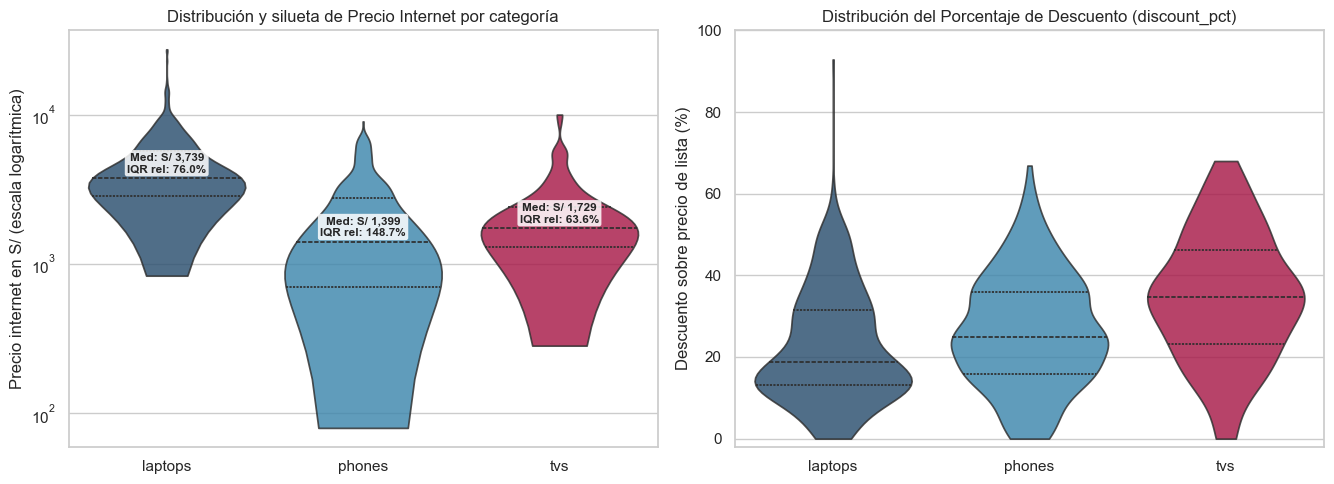

**Interpretación de los gráficos de violín.**
- En **televisores (`tvs`)**, el violín presenta una **base ancha y muy compacta entre S/ 1,000 y S/ 2,400** (donde se concentra la mitad central del catálogo por la estandarización de paneles LED/QLED de 43" a 65"), estrechándose abruptamente hacia los modelos OLED/MiniLED de gran formato.
- En **celulares (`phones`)**, el violín es **alargado y multimodal**, mostrando tres abultamientos definidos que corresponden a los smartphones de entrada (S/ 400–800), gama media (S/ 1,200–2,000) y flagships premium (S/ 3,500–7,000).
- En **laptops (`laptops`)**, la masa principal se ubica entre S/ 2,500 y S/ 5,700, con una cola superior extendida hasta S/ 27,346 correspondiente a workstations y laptops gamer de alto rendimiento.

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
palette_cat = {"laptops": "#1f4e79", "phones": "#2b8cbe", "tvs": "#bf0140"}

# Panel izquierdo: Violín de internet_price (escala logarítmica para visualizar silueta completa y multimodalidad)
sns.violinplot(
    data=df, x="category", y="internet_price", order=CATS,
    palette=palette_cat, inner="quartile", cut=0, alpha=0.82, ax=axes[0]
)
axes[0].set_yscale("log")
axes[0].set_title("Distribución y silueta de Precio Internet por categoría")
axes[0].set_xlabel("")
axes[0].set_ylabel("Precio internet en S/ (escala logarítmica)")
for idx, row in tabla_dispersion.iterrows():
    axes[0].text(
        idx, row["median_soles"] * 1.07,
        f"Med: S/ {row['median_soles']:,.0f}\nIQR rel: {row['iqr_relativo_pct']}%",
        ha="center", va="bottom", fontsize=8.5, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85, edgecolor="none")
    )

# Panel derecho: Violín de discount_pct por categoría
sns.violinplot(
    data=df, x="category", y="discount_pct", order=CATS,
    palette=palette_cat, inner="quartile", cut=0, alpha=0.82, ax=axes[1]
)
axes[1].set_title("Distribución del Porcentaje de Descuento (discount_pct)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Descuento sobre precio de lista (%)")
axes[1].set_ylim(-2, 100)

plt.tight_layout()
savefig("ana_01_violin_precios_categoria")
plt.show()

say(
    "**Interpretación de los gráficos de violín.**\n"
    "- En **televisores (`tvs`)**, el violín presenta una **base ancha y muy compacta entre S/ 1,000 y S/ 2,400** (donde se concentra la mitad central del catálogo por la estandarización de paneles LED/QLED de 43\" a 65\"), estrechándose abruptamente hacia los modelos OLED/MiniLED de gran formato.\n"
    "- En **celulares (`phones`)**, el violín es **alargado y multimodal**, mostrando tres abultamientos definidos que corresponden a los smartphones de entrada (S/ 400–800), gama media (S/ 1,200–2,000) y flagships premium (S/ 3,500–7,000).\n"
    "- En **laptops (`laptops`)**, la masa principal se ubica entre S/ 2,500 y S/ 5,700, con una cola superior extendida hasta S/ 27,346 correspondiente a workstations y laptops gamer de alto rendimiento."
)

## 2. Comparación de Descuentos por Categoría y Nivel de Gama (`low`, `mid`, `high`)

Estratificando por la variable `prices_category` (terciles empíricos dentro de cada categoría), analizamos si la agresividad de los descuentos es uniforme o si depende del segmento de precio.

,category,prices_category,n,pct_con_descuento,mediana_precio_soles,mediana_desc_pct,iqr_desc_pct,mediana_ahorro_soles,iqr_ahorro_soles
0,laptops,low,155,95.5,2499.0,23.33,20.27,620.00,804.04
1,laptops,mid,136,99.3,3799.0,18.74,20.70,977.45,1267.75
2,laptops,high,142,94.4,6599.0,17.24,13.92,1388.50,1469.50
3,phones,low,146,97.3,519.5,29.39,22.05,200.00,222.00
4,phones,mid,145,97.9,1399.0,24.22,16.18,420.00,400.00
5,phones,high,146,94.5,3379.0,23.58,20.97,965.00,1206.25
6,tvs,low,57,100.0,1099.0,37.02,20.32,580.00,451.00
7,tvs,mid,55,90.9,1729.0,34.80,16.95,900.00,675.00
8,tvs,high,55,100.0,3299.0,31.25,24.57,1700.00,2030.00


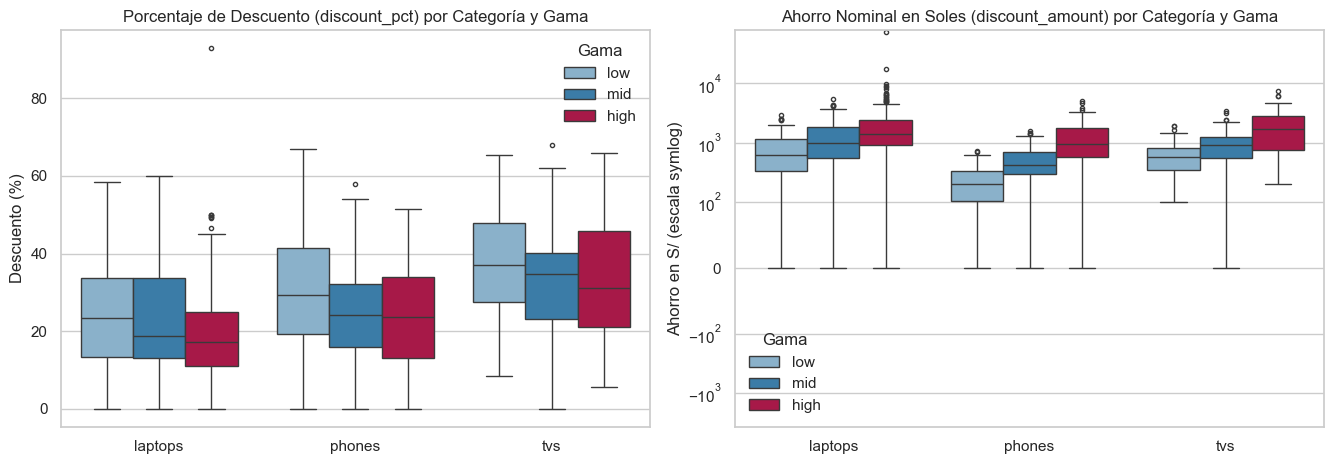

**Hallazgo clave sobre la estructura de rebajas por gama.**
1. **En porcentaje (`discount_pct`), la gama baja (`low`) recibe siempre los mayores descuentos medianos** en las tres categorías: **37.02 %** en televisores (vs. 31.25 % en gama alta), **29.39 %** en celulares (vs. 23.58 % en gama alta) y **23.33 %** en laptops (vs. 17.24 % en gama alta).
2. **En soles (`discount_amount`), el comportamiento se invierte**: debido al alto valor base de los equipos premium, el ahorro mediano en gama alta alcanza **S/ 1,700** en televisores, **S/ 1,388.50** en laptops y **S/ 965** en celulares.

In [4]:
resumen_gamas = (
    df.groupby(["category", "prices_category"], observed=True)
    .agg(
        n=("product", "size"),
        pct_con_descuento=("has_discount", lambda s: round(s.mean() * 100, 1)),
        mediana_precio_soles=("internet_price", "median"),
        mediana_desc_pct=("discount_pct", "median"),
        iqr_desc_pct=("discount_pct", lambda s: round(s.quantile(0.75) - s.quantile(0.25), 2)),
        mediana_ahorro_soles=("discount_amount", "median"),
        iqr_ahorro_soles=("discount_amount", lambda s: round(s.quantile(0.75) - s.quantile(0.25), 2)),
    )
    .reindex(pd.MultiIndex.from_product([CATS, TIERS], names=["category", "prices_category"]))
    .reset_index()
)
resumen_gamas.to_csv(ANA_DIR / "descuentos_por_categoria_y_gama.csv", index=False, encoding="utf-8")
display(resumen_gamas)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
palette_tiers = {"low": "#7fb3d5", "mid": "#2980b9", "high": "#bf0140"}

sns.boxplot(
    data=df, x="category", y="discount_pct", hue="prices_category",
    order=CATS, hue_order=TIERS, palette=palette_tiers, fliersize=3, ax=axes[0]
)
axes[0].set_title("Porcentaje de Descuento (discount_pct) por Categoría y Gama")
axes[0].set_xlabel("")
axes[0].set_ylabel("Descuento (%)")
axes[0].legend(title="Gama", frameon=False)

sns.boxplot(
    data=df, x="category", y="discount_amount", hue="prices_category",
    order=CATS, hue_order=TIERS, palette=palette_tiers, fliersize=3, ax=axes[1]
)
axes[1].set_yscale("symlog", linthresh=100)
axes[1].set_title("Ahorro Nominal en Soles (discount_amount) por Categoría y Gama")
axes[1].set_xlabel("")
axes[1].set_ylabel("Ahorro en S/ (escala symlog)")
axes[1].legend(title="Gama", frameon=False)

plt.tight_layout()
savefig("ana_02_boxplots_descuento_gama")
plt.show()

say(
    "**Hallazgo clave sobre la estructura de rebajas por gama.**\n"
    "1. **En porcentaje (`discount_pct`), la gama baja (`low`) recibe siempre los mayores descuentos medianos** en las tres categorías: "
    "**37.02 %** en televisores (vs. 31.25 % en gama alta), **29.39 %** en celulares (vs. 23.58 % en gama alta) y **23.33 %** en laptops (vs. 17.24 % en gama alta).\n"
    "2. **En soles (`discount_amount`), el comportamiento se invierte**: debido al alto valor base de los equipos premium, el ahorro mediano en gama alta alcanza **S/ 1,700** en televisores, **S/ 1,388.50** en laptops y **S/ 965** en celulares."
)

## 3. Relación entre Precio Internet y Descuento Porcentual (Correlación)

Para verificar estadísticamente si los productos más costosos presentan precios más rígidos (menores descuentos porcentuales), calculamos la correlación lineal de Pearson ($r$) y de rangos de Spearman ($\rho$) entre `internet_price` y `discount_pct` dentro de cada categoría.

,category,n,pearson_r,pearson_pvalue,spearman_rho,spearman_pvalue
0,laptops,433,-0.129,0.007402,-0.157,0.00108
1,phones,437,-0.274,0.000000,-0.258,0.00000
2,tvs,167,-0.176,0.023116,-0.185,0.01684


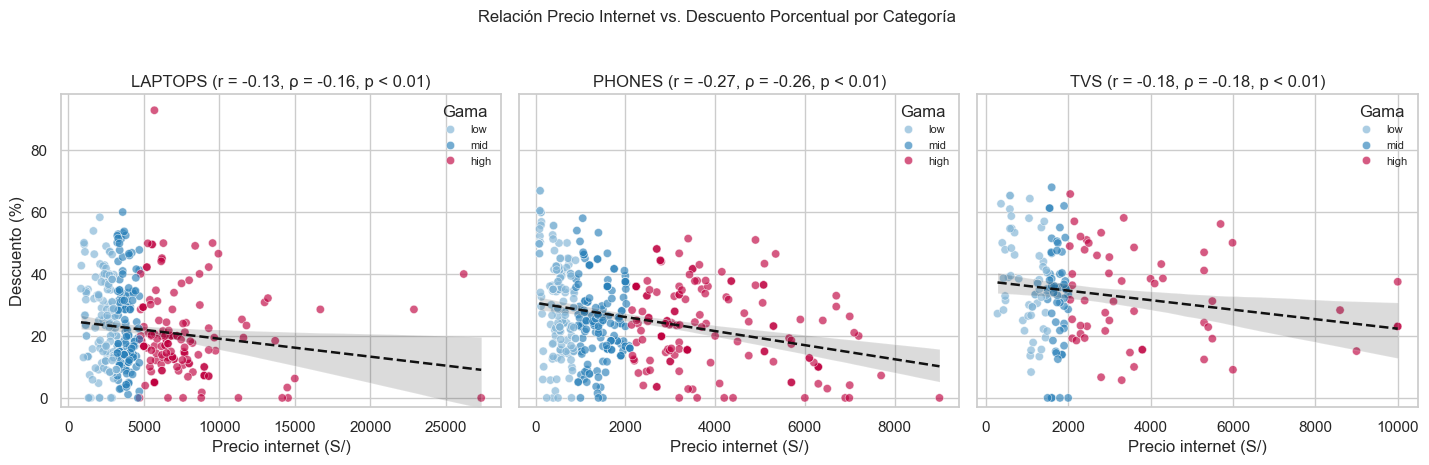

**Interpretación.** Las tres categorías exhiben una **correlación negativa y estadísticamente significativa ($p < 0.01$)** entre el precio de venta y el porcentaje de descuento, siendo más pronunciada en **celulares ($r = -0.27$, $ho = -0.26$)**: a medida que aumenta el precio del equipo, el descuento porcentual disminuye. Esto demuestra que las marcas líderes protegen el precio de sus modelos *flagship* de gama alta, mientras que la competencia promocional por porcentaje se libra en las gamas de entrada y media.

In [5]:
corr_rows = []
for cat in CATS:
    sub = df[df["category"] == cat]
    r_p, p_p = stats.pearsonr(sub["internet_price"], sub["discount_pct"])
    r_s, p_s = stats.spearmanr(sub["internet_price"], sub["discount_pct"])
    corr_rows.append({
        "category": cat,
        "n": len(sub),
        "pearson_r": round(r_p, 3),
        "pearson_pvalue": round(p_p, 6),
        "spearman_rho": round(r_s, 3),
        "spearman_pvalue": round(p_s, 6),
    })
corr_df = pd.DataFrame(corr_rows)
corr_df.to_csv(ANA_DIR / "correlacion_precio_descuento.csv", index=False, encoding="utf-8")
display(corr_df)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.5), sharey=True)
for ax, cat in zip(axes, CATS):
    sub = df[df["category"] == cat]
    row = corr_df[corr_df["category"] == cat].iloc[0]
    sns.scatterplot(
        data=sub, x="internet_price", y="discount_pct", hue="prices_category",
        hue_order=TIERS, palette=palette_tiers, alpha=0.65, s=36, ax=ax
    )
    sns.regplot(
        data=sub, x="internet_price", y="discount_pct",
        scatter=False, color="#111111", line_kws={"linewidth": 1.8, "linestyle": "--"}, ax=ax
    )
    ax.set_title(f"{cat.upper()} (r = {row['pearson_r']:.2f}, ρ = {row['spearman_rho']:.2f}, p < 0.01)")
    ax.set_xlabel("Precio internet (S/)")
    ax.set_ylabel("Descuento (%)" if cat == "laptops" else "")
    ax.set_ylim(-3, 98)
    ax.legend(title="Gama", frameon=False, fontsize=8)

plt.suptitle("Relación Precio Internet vs. Descuento Porcentual por Categoría", fontsize=12, y=1.03)
plt.tight_layout()
savefig("ana_03_scatter_precio_descuento")
plt.show()

say(
    f"**Interpretación.** Las tres categorías exhiben una **correlación negativa y estadísticamente significativa ($p < 0.01$)** entre el precio de venta y el porcentaje de descuento, siendo más pronunciada en **celulares ($r = {corr_df.loc[1, 'pearson_r']:.2f}$, $\rho = {corr_df.loc[1, 'spearman_rho']:.2f}$)**: a medida que aumenta el precio del equipo, el descuento porcentual disminuye. Esto demuestra que las marcas líderes protegen el precio de sus modelos *flagship* de gama alta, mientras que la competencia promocional por porcentaje se libra en las gamas de entrada y media."
)

## 4. Veracidad de Descuentos y Anomalías: Descuentos Inflados, Reacondicionados y Combos

Finalmente, auditamos tres fenómenos comerciales que afectan la lectura de precios y descuentos:
1. **Descuentos extremos o inflados ($\ge 60\%$):** publicaciones donde el vendedor declara un `list_price` desproporcionado respecto al valor real de mercado para aparentar una rebaja masiva (efecto de *anclaje publicitario* o error de digitación).
2. **Impacto de los equipos reacondicionados (`is_refurbished == 1`):** concentrados en celulares (`17.4 %` de la categoría) y en particular en la marca **APPLE**.
3. **Impacto de los combos promocionales (`is_bundle == 1`):** publicaciones que incluyen accesorios adicionales (`+ AUDÍFONOS`, `+ MOCHILA`, `+ BARRA DE SONIDO`).

In [6]:
inflados = df[df["discount_pct"] >= 60.0].sort_values("discount_pct", ascending=False)[
    ["category", "brand", "seller", "seller_type", "list_price", "internet_price", "discount_pct", "product"]
]
inflados.to_csv(ANA_DIR / "descuentos_extremos_auditados.csv", index=False, encoding="utf-8")
print(f"Publicaciones con descuento >= 60%: {len(inflados)} casos (1 caso > 70%):")
display(inflados.head(10))

# Comparación Apple Nuevos vs Reacondicionados en celulares
apple_phones = df[(df["category"] == "phones") & (df["brand"] == "APPLE")]
comp_apple = apple_phones.groupby("is_refurbished").agg(
    publicaciones=("product", "size"),
    mediana_list_price=("list_price", "median"),
    mediana_internet_price=("internet_price", "median"),
    iqr_internet_price=("internet_price", lambda s: round(s.quantile(0.75) - s.quantile(0.25), 2)),
    mediana_desc_pct=("discount_pct", "median"),
).rename(index={0: "Nuevo (0)", 1: "Reacondicionado (1)"})
print("Efecto de is_refurbished dentro de celulares APPLE:")
display(comp_apple)

Publicaciones con descuento >= 60%: 16 casos (1 caso > 70%):


,category,brand,seller,seller_type,list_price,internet_price,discount_pct,product
810,laptops,LENOVO,IVANCE ELECTRONIC ONLINE,MARKETPLACE_SELLER,79999.0,5699.0,92.88,"LAPTOP LOQ 15AHP10 AMD RYZEN 7 250 16GB DDR5 512GB RTX 5050 8GB 15.6"" FHD 144HZ - 83JG..."
938,tvs,LG,ELECTROHOGAR,MARKETPLACE_SELLER,4999.0,1599.0,68.01,"TELEVISOR 65"" NANO 4K UHD AI SMART TV 65NU800BPSB - 2026"
295,phones,LOGIC,TEC DTEEC,MARKETPLACE_SELLER,299.0,99.0,66.89,CELULAR BASICO C10L 4G DUAL SIM - NEGRO
173,phones,LOGIC,D'TEEC CORPORACION. CJ S.A.C,MARKETPLACE_SELLER,299.0,99.0,66.89,CELULAR BASICO C10L 4G DUAL SIM - NEGRO
1007,tvs,TCL,IMPORT ELECTRO JB,MARKETPLACE_SELLER,5999.0,2049.0,65.84,TELEVISOR QLED 75 UHD 4K SMART TV GOOGLE 75T6C
978,tvs,LG,IVANCE ELECTRONIC ONLINE,MARKETPLACE_SELLER,1699.0,589.0,65.33,TELEVISOR 32 SMART TV LED 32LQ600BPSA
1001,tvs,LG,SEVEN SHOP,MARKETPLACE_SELLER,1699.0,589.0,65.33,TELEVISOR 32 SMART TV LED 32LQ600BPSA
972,tvs,GENERICO,VICTORIA ILIMITADA,MARKETPLACE_SELLER,2999.0,1069.0,64.35,TELEVISOR JVC 50 UHD 4K GOOGLE TV LT-50KB538
870,tvs,CAIXUN,CAIXUN TIENDA OFICIAL,MARKETPLACE_SELLER,989.0,369.0,62.69,SMART TV LED 32 HD ROKU TV C32V1HR
885,tvs,JVC,SODIMAC,FALABELLA_DIRECT,4999.9,1899.9,62.00,"TELEVISOR 75"" QD MINILED 4K GOOGLE TV LT-75KM958"


Efecto de is_refurbished dentro de celulares APPLE:


,publicaciones,mediana_list_price,mediana_internet_price,iqr_internet_price,mediana_desc_pct
is_refurbished,,,,,
Nuevo (0),46,5999.0,5069.0,2925.0,25.160
Reacondicionado (1),44,2549.0,1999.0,1118.0,24.025


<>:35: SyntaxWarning: invalid escape sequence '\g'
<>:35: SyntaxWarning: invalid escape sequence '\g'
C:\Users\axelr\AppData\Local\Temp\ipykernel_5880\2708282396.py:35: SyntaxWarning: invalid escape sequence '\g'
  "1. **Descuento inflado extremo (> 70 %):** La laptop Lenovo LOQ 15AHP10 publicada por `IVANCE ELECTRONIC ONLINE` registra un `list_price` de **S/ 79,999** frente a un `internet_price` de **S/ 5,699** (rebaja artificial de **92.88 %**), producto de un error de digitación del vendedor (S/ 79,999 en lugar de S/ 7,999, con lo cual su descuento real sería 28.8 %). Asimismo, 15 de los 16 casos con descuentos $\ge 60\%$ provienen de *sellers* externos que inflan el precio referencial como anclaje.\n"


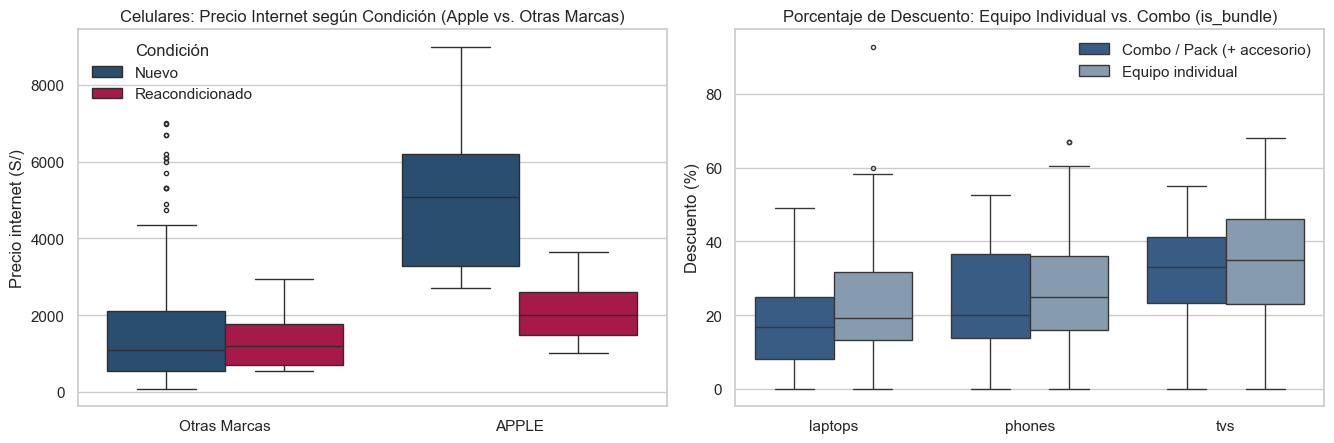

**Conclusiones de la auditoría de anomalías y banderas.**
1. **Descuento inflado extremo (> 70 %):** La laptop Lenovo LOQ 15AHP10 publicada por `IVANCE ELECTRONIC ONLINE` registra un `list_price` de **S/ 79,999** frente a un `internet_price` de **S/ 5,699** (rebaja artificial de **92.88 %**), producto de un error de digitación del vendedor (S/ 79,999 en lugar de S/ 7,999, con lo cual su descuento real sería 28.8 %). Asimismo, 15 de los 16 casos con descuentos $\ge 60\%$ provienen de *sellers* externos que inflan el precio referencial como anclaje.
2. **Aislamiento de reacondicionados (`is_refurbished`):** De los 76 celulares reacondicionados, **69 son iPhones de Apple** (el 58.5 % de los 118 celulares Apple del catálogo). Mientras un iPhone nuevo tiene una mediana de **S/ 4,499**, un iPhone reacondicionado baja a **S/ 1,739** (-61.3 %). Sin la bandera `is_refurbished`, estos equipos de segunda selección distorsionarían hacia abajo el piso de precios de Apple.
3. **Efecto de los combos (`is_bundle`):** Los paquetes promocionales representan el 9.4 % del catálogo (97 publicaciones) y mantienen descuentos porcentuales ligeramente más moderados que los equipos individuales (mediana de 20.1 % vs. 25.0 % en celulares), ya que la promoción se entrega mediante el accesorio incluido (audífonos, smartwatch o barra de sonido) en lugar de rebajar agresivamente el precio nominal.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

# Panel izquierdo: Celulares Nuevos vs Reacondicionados (Apple vs Resto de marcas)
phones_df = df[df["category"] == "phones"].copy()
phones_df["segmento_marca"] = np.where(phones_df["brand"] == "APPLE", "APPLE", "Otras Marcas")
phones_df["condicion"] = phones_df["is_refurbished"].map({0: "Nuevo", 1: "Reacondicionado"})

sns.boxplot(
    data=phones_df, x="segmento_marca", y="internet_price", hue="condicion",
    palette={"Nuevo": "#1f4e79", "Reacondicionado": "#bf0140"}, fliersize=3, ax=axes[0]
)
axes[0].set_title("Celulares: Precio Internet según Condición (Apple vs. Otras Marcas)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Precio internet (S/)")
axes[0].legend(title="Condición", frameon=False)

# Panel derecho: Combos (is_bundle) vs Individuales por categoría
df_bundle = df.copy()
df_bundle["Modalidad"] = df_bundle["is_bundle"].map({0: "Equipo individual", 1: "Combo / Pack (+ accesorio)"})
sns.boxplot(
    data=df_bundle, x="category", y="discount_pct", hue="Modalidad",
    order=CATS, palette={"Equipo individual": "#7f9cb5", "Combo / Pack (+ accesorio)": "#2b5c8f"}, fliersize=3, ax=axes[1]
)
axes[1].set_title("Porcentaje de Descuento: Equipo Individual vs. Combo (is_bundle)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Descuento (%)")
axes[1].legend(title="", frameon=False)

plt.tight_layout()
savefig("ana_04_anomalias_reacondicionados_combos")
plt.show()

say(
    "**Conclusiones de la auditoría de anomalías y banderas.**\n"
    "1. **Descuento inflado extremo (> 70 %):** La laptop Lenovo LOQ 15AHP10 publicada por `IVANCE ELECTRONIC ONLINE` registra un `list_price` de **S/ 79,999** frente a un `internet_price` de **S/ 5,699** (rebaja artificial de **92.88 %**), producto de un error de digitación del vendedor (S/ 79,999 en lugar de S/ 7,999, con lo cual su descuento real sería 28.8 %). Asimismo, 15 de los 16 casos con descuentos $\ge 60\%$ provienen de *sellers* externos que inflan el precio referencial como anclaje.\n"
    "2. **Aislamiento de reacondicionados (`is_refurbished`):** De los 76 celulares reacondicionados, **69 son iPhones de Apple** (el 58.5 % de los 118 celulares Apple del catálogo). Mientras un iPhone nuevo tiene una mediana de **S/ 4,499**, un iPhone reacondicionado baja a **S/ 1,739** (-61.3 %). Sin la bandera `is_refurbished`, estos equipos de segunda selección distorsionarían hacia abajo el piso de precios de Apple.\n"
    "3. **Efecto de los combos (`is_bundle`):** Los paquetes promocionales representan el 9.4 % del catálogo (97 publicaciones) y mantienen descuentos porcentuales ligeramente más moderados que los equipos individuales (mediana de 20.1 % vs. 25.0 % en celulares), ya que la promoción se entrega mediante el accesorio incluido (audífonos, smartwatch o barra de sonido) en lugar de rebajar agresivamente el precio nominal."
)